# Заняття 9 · LIVE DEMO 1
## SORT vs BYTE на синтетичній сцені з відомим GT

**Що порівнюємо.** Один і той самий симульований детектор, однаковий життєвий цикл треку (`n_init`, `max_age`, поріг народження). Відрізняється **лише асоціація**:

| Варіант | Асоціація |
|---|---|
| `SORT` | тільки бокси з `score ≥ 0.6` |
| `BYTE` | + другий етап: слабкі бокси `0.1 ≤ score < 0.6` для треків, що були активні на попередньому кадрі |
| `BYTE (центр)` | те саме, але слабкий бокс оновлює лише **центр** треку, а не розмір |

**Чому синтетика.** GT відомий точно, тож кожне число можна перевірити, а демо відтворюється без жодних даних. Сцена: 10 цілей із маневровим рухом, два укриття, у яких детектор не втрачає ціль, а дає слабкий score і обрізаний бокс.

Посилання на слайди — розділ 02 «Алгоритми MOT» (ByteTrack, пороги) і розділ 01 (метрики). Мітка на слайдах: «ДЕМО 01 · lesson09_demo1_sort_vs_byte.ipynb».

Спільні графіки — у `panels.py`, він має лежати поруч із ноутбуком.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from panels import PAL, set_style, bars_with_err, id_timeline

set_style()
C = dict(sort=PAL['re'], byte=PAL['or_'], bytec=PAL['te'], gt=PAL['bl'], occ=PAL['mu'])

### 1. Сцена і симульований детектор

In [2]:
import numpy as np
from scipy.optimize import linear_sum_assignment

W, H, T = 1280, 720, 300
OCCLUDERS = [(360, 480), (800, 920)]
SHRINK = 0.7   # в укритті видно лише частину цілі   # x-діапазони укриттів (дерева / будівлі)


def make_gt(n_obj=10, seed=0, accel=0.35):
    """GT: список кадрів, у кожному (id, cx, cy, w, h).
    Рух маневровий: швидкість змінюється випадково (accel, px/кадр²),
    тому екстраполяція Калмана за укриттям поступово «з'їжджає»."""
    rng = np.random.default_rng(seed)
    frames = [[] for _ in range(T)]
    for oid in range(n_obj):
        left = oid % 2 == 0
        cx = rng.uniform(-60, 40) if left else rng.uniform(W - 40, W + 60)
        sgn = 1 if left else -1
        vx = rng.uniform(2.5, 5.0) * sgn
        cy, vy = rng.uniform(140, H - 160), rng.uniform(-0.3, 0.3)
        w = rng.uniform(40, 70)
        h = w * rng.uniform(0.55, 0.8)
        t0 = int(rng.integers(0, 90))
        for t in range(t0, T):
            vx = np.clip(vx + rng.normal(0, accel), 1.5, 7.0) if sgn > 0 else np.clip(vx + rng.normal(0, accel), -7.0, -1.5)
            vy = np.clip(vy + rng.normal(0, accel * 0.6), -2.5, 2.5)
            cx, cy = cx + vx, cy + vy
            if not 60 <= cy <= H - 60:          # відбиття від меж кадру замість «прилипання»
                vy, cy = -vy, np.clip(cy, 60, H - 60)
            if -w < cx < W + w:
                frames[t].append((oid, cx, cy, w, h))
    return frames


def occluded(cx):
    return any(a <= cx <= b for a, b in OCCLUDERS)


def detect(frames, p_vis=0.97, p_occ=0.8, occ_score=(0.15, 0.45), fp_rate=1.5, jitter=2.0, seed=0):
    """Симульований детектор: в укритті ціль не зникає, а дає слабкий score і обрізаний бокс."""
    rng = np.random.default_rng(seed + 1000)
    out = []
    for objs in frames:
        D = []
        for oid, cx, cy, w, h in objs:
            occ = occluded(cx)
            if rng.random() > (p_occ if occ else p_vis):
                continue
            s = rng.uniform(*occ_score) if occ else rng.uniform(0.6, 0.95)
            bw = w * (SHRINK if occ else 1.0)
            D.append([cx + rng.normal(0, jitter), cy + rng.normal(0, jitter),
                      bw * (1 + rng.normal(0, 0.03)), h * (1 + rng.normal(0, 0.03)), s])
        for _ in range(rng.poisson(fp_rate)):
            D.append([rng.uniform(0, W), rng.uniform(0, H), rng.uniform(30, 70),
                      rng.uniform(20, 50), rng.uniform(0.1, 0.5)])
        out.append(np.array(D, dtype=float).reshape(-1, 5))
    return out




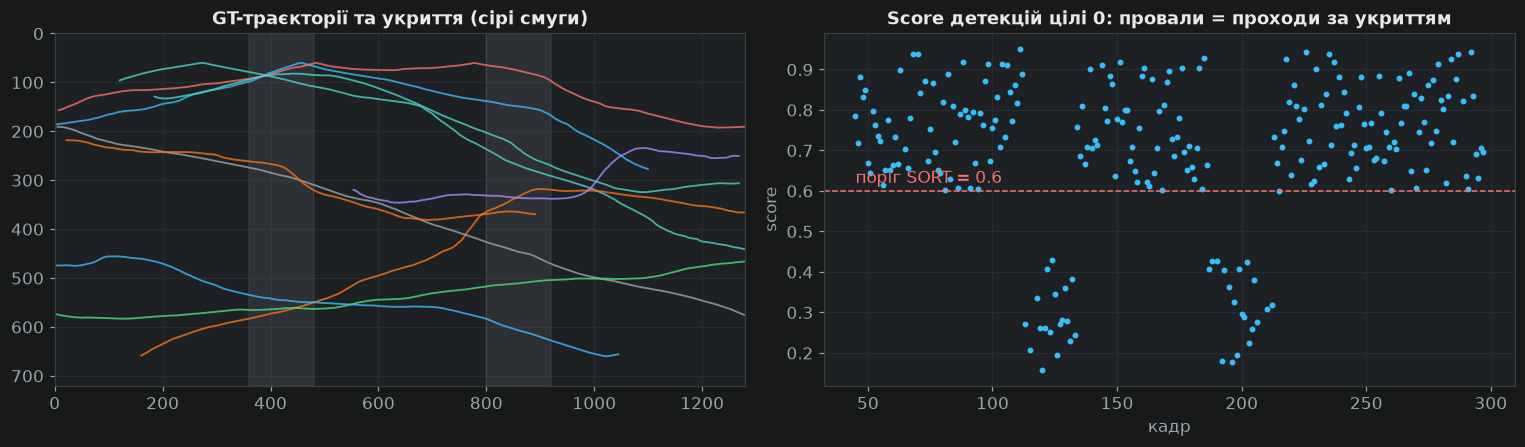

In [3]:
frames = make_gt(seed=0)
dets = detect(frames, seed=0)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for a, b in OCCLUDERS:
    ax[0].axvspan(a, b, color=C['occ'], alpha=0.12)
tracks_gt = {}
for t, objs in enumerate(frames):
    for oid, cx, cy, w, h in objs:
        tracks_gt.setdefault(oid, []).append((cx, cy))
for oid, pts in tracks_gt.items():
    p = np.array(pts)
    ax[0].plot(p[:, 0], p[:, 1], lw=1.2, alpha=0.8)
ax[0].set_xlim(0, W); ax[0].set_ylim(H, 0)
ax[0].set_title('GT-траєкторії та укриття (сірі смуги)')

# score однієї цілі в часі
oid = 0
ts, ss = [], []
for t, objs in enumerate(frames):
    o = [x for x in objs if x[0] == oid]
    if not o or len(dets[t]) == 0:
        continue
    _, cx, cy, w, h = o[0]
    d = dets[t]
    k = np.argmin(np.hypot(d[:, 0] - cx, d[:, 1] - cy))
    if np.hypot(d[k, 0] - cx, d[k, 1] - cy) < 15:
        ts.append(t); ss.append(d[k, 4])
ax[1].scatter(ts, ss, s=8, color=C['gt'])
ax[1].axhline(0.6, color=C['sort'], ls='--', lw=1)
ax[1].text(ts[0], 0.62, 'поріг SORT = 0.6', color=C['sort'])
ax[1].set_title(f'Score детекцій цілі {oid}: провали = проходи за укриттям')
ax[1].set_xlabel('кадр'); ax[1].set_ylabel('score')
plt.tight_layout(); plt.show()

### 2. Трекер: Kalman (constant velocity) + IoU + Hungarian

Стан треку — `(cx, cy, w, h)` і їхні швидкості. Параметр `mode` вмикає другий етап асоціації ByteTrack, `low_size_update` керує тим, чи оновлює слабкий бокс розмір треку.

In [4]:
def iou_matrix(A, B):
    """IoU між боксами у форматі (cx, cy, w, h)."""
    if len(A) == 0 or len(B) == 0:
        return np.zeros((len(A), len(B)))
    A, B = np.asarray(A, float), np.asarray(B, float)
    ax1, ay1, ax2, ay2 = A[:, 0] - A[:, 2] / 2, A[:, 1] - A[:, 3] / 2, A[:, 0] + A[:, 2] / 2, A[:, 1] + A[:, 3] / 2
    bx1, by1, bx2, by2 = B[:, 0] - B[:, 2] / 2, B[:, 1] - B[:, 3] / 2, B[:, 0] + B[:, 2] / 2, B[:, 1] + B[:, 3] / 2
    iw = np.clip(np.minimum(ax2[:, None], bx2[None]) - np.maximum(ax1[:, None], bx1[None]), 0, None)
    ih = np.clip(np.minimum(ay2[:, None], by2[None]) - np.maximum(ay1[:, None], by1[None]), 0, None)
    inter = iw * ih
    ua = (A[:, 2] * A[:, 3])[:, None] + (B[:, 2] * B[:, 3])[None] - inter
    return inter / np.maximum(ua, 1e-9)


class Track:
    def __init__(self, tid, z):
        self.id = tid
        self.x = np.r_[z[:4], 0, 0, 0, 0].astype(float)
        self.P = np.diag([10, 10, 10, 10, 100, 100, 10, 10]).astype(float)
        self.hits, self.since = 1, 0
        self.confirmed = False

    F = np.eye(8); F[:4, 4:] = np.eye(4)
    Hm = np.eye(4, 8)
    Q = np.diag([1, 1, 1, 1, 0.5, 0.5, 0.05, 0.05])
    R = np.diag([4, 4, 9, 9])

    def predict(self):
        self.x = self.F @ self.x
        self.P = self.F @ self.P @ self.F.T + self.Q
        self.since += 1

    def update(self, z, n_init):
        y = z[:4] - self.Hm @ self.x
        S = self.Hm @ self.P @ self.Hm.T + self.R
        K = self.P @ self.Hm.T @ np.linalg.inv(S)
        self.x = self.x + K @ y
        self.P = (np.eye(8) - K @ self.Hm) @ self.P
        self.hits += 1
        self.since = 0
        if self.hits >= n_init:
            self.confirmed = True

    def box(self):
        return self.x[:4].copy()


def associate(tracks, dets, max_cost):
    if len(tracks) == 0 or len(dets) == 0:
        return [], list(range(len(tracks))), list(range(len(dets)))
    cost = 1 - iou_matrix([t.box() for t in tracks], dets[:, :4])
    r, c = linear_sum_assignment(cost)
    m = [(i, j) for i, j in zip(r, c) if cost[i, j] <= max_cost]
    mt = {i for i, _ in m}
    md = {j for _, j in m}
    return m, [i for i in range(len(tracks)) if i not in mt], [j for j in range(len(dets)) if j not in md]


def run_tracker(dets, mode="byte", high=0.6, low=0.1, new_thr=0.7,
                match1=0.8, match2=0.5, n_init=3, max_age=30, low_size_update=True):
    """mode='sort': лише бокси з score ≥ high. mode='byte': + другий етап по слабких боксах.
    Життєвий цикл однаковий — відрізняється тільки асоціація.
    low_size_update=False: у другому етапі оновлюємо лише центр, а не розмір треку."""
    tracks, nid, out = [], 1, []
    for t, D in enumerate(dets):
        for tr in tracks:
            tr.predict()
        hi = D[D[:, 4] >= high]
        lo = D[(D[:, 4] >= low) & (D[:, 4] < high)]
        m1, ut, ud = associate(tracks, hi, match1)
        for i, j in m1:
            tracks[i].update(hi[j], n_init)
        rest = [tracks[i] for i in ut]
        if mode == "byte":
            # як у ByteTrack: другий етап лише для треків, що були активні на попередньому кадрі
            active = [tr for tr in rest if tr.since == 1 and tr.confirmed]
            m2, _, _ = associate(active, lo, match2)
            for i, j in m2:
                z = lo[j].copy()
                if not low_size_update:
                    # слабкий бокс часто обрізаний укриттям: беремо з нього лише центр
                    z[2:4] = active[i].box()[2:4]
                active[i].update(z, n_init)
        # непідтверджені треки без пари видаляються одразу
        tracks = [tr for tr in tracks if not (not tr.confirmed and tr.since > 0)]
        for j in ud:
            if hi[j, 4] >= new_thr:
                tracks.append(Track(nid, hi[j]))
                nid += 1
        tracks = [tr for tr in tracks if tr.since <= max_age]
        for tr in tracks:
            if tr.confirmed and tr.since == 0:
                out.append((t, tr.id, *tr.box()))
    return out




### 3. Метрики

`evaluate` рахує CLEAR MOT (MOTA, ID switch), IDF1 і середню кількість різних ID на один GT-об'єкт. Це спрощена реалізація для демо; для звітів і ДЗ беріть **TrackEval**. У §5 і §7 HOTA з розкладом на DetA / AssA рахує саме він (`run_trackeval` з `mdmt.py`); його MOTA та IDF1 на цих сценах збігаються з `evaluate`.

In [5]:
def evaluate(frames, hyp, iou_thr=0.5):
    """CLEAR MOT (MOTA, IDSW), IDF1 та середня кількість ID на один GT-об'єкт."""
    hyp_by_t = {}
    for t, tid, *b in hyp:
        hyp_by_t.setdefault(t, []).append((tid, b))
    gt_total = sum(len(f) for f in frames)
    hyp_total = len(hyp)
    fn = fp = idsw = 0
    last = {}
    ids_per_gt = {}
    pair_count = {}
    for t, objs in enumerate(frames):
        H_ = hyp_by_t.get(t, [])
        g_ids = [o[0] for o in objs]
        h_ids = [h[0] for h in H_]
        M = iou_matrix([o[1:] for o in objs], [h[1] for h in H_])
        # лічильник для IDF1: будь-яка пара з IoU ≥ поріг
        for gi, hi in zip(*np.where(M >= iou_thr)):
            key = (g_ids[gi], h_ids[hi])
            pair_count[key] = pair_count.get(key, 0) + 1
        matched_g = set()
        matched_h = set()
        if M.size:
            r, c = linear_sum_assignment(-M)
            for gi, hi in zip(r, c):
                if M[gi, hi] >= iou_thr:
                    g, h = g_ids[gi], h_ids[hi]
                    matched_g.add(gi); matched_h.add(hi)
                    if g in last and last[g] != h:
                        idsw += 1
                    last[g] = h
                    ids_per_gt.setdefault(g, set()).add(h)
        fn += len(objs) - len(matched_g)
        fp += len(H_) - len(matched_h)
    # IDF1: глобальне двочасткове призначення GT-id ↔ track-id
    gids = sorted({k[0] for k in pair_count})
    hids = sorted({k[1] for k in pair_count})
    idtp = 0
    if gids:
        C = np.zeros((len(gids), len(hids)))
        for (g, h), v in pair_count.items():
            C[gids.index(g), hids.index(h)] = v
        r, c = linear_sum_assignment(-C)
        idtp = C[r, c].sum()
    idf1 = 2 * idtp / max(gt_total + hyp_total, 1)
    mota = 1 - (fn + fp + idsw) / max(gt_total, 1)
    frag = np.mean([len(v) for v in ids_per_gt.values()]) if ids_per_gt else 0
    return dict(MOTA=mota, IDF1=idf1, IDSW=idsw, FP=fp, FN=fn, IDs_per_GT=frag)


### 4. Один прогін

In [6]:
VARIANTS = {
    'SORT':         dict(mode='sort'),
    'BYTE':         dict(mode='byte'),
    'BYTE (центр)': dict(mode='byte', low_size_update=False),
}
hyps = {k: run_tracker(dets, **v) for k, v in VARIANTS.items()}
rows = {k: evaluate(frames, h) for k, h in hyps.items()}
print(f"{'':14s} {'MOTA':>6s} {'IDF1':>6s} {'IDSW':>5s} {'FN':>5s} {'ID/GT':>6s}")
for k, r in rows.items():
    print(f"{k:14s} {r['MOTA']:6.3f} {r['IDF1']:6.3f} {r['IDSW']:5d} {r['FN']:5d} {r['IDs_per_GT']:6.2f}")

                 MOTA   IDF1  IDSW    FN  ID/GT
SORT            0.772  0.623     8   562   1.80
BYTE            0.802  0.593     9   485   1.90
BYTE (центр)    0.798  0.668     7   498   1.70


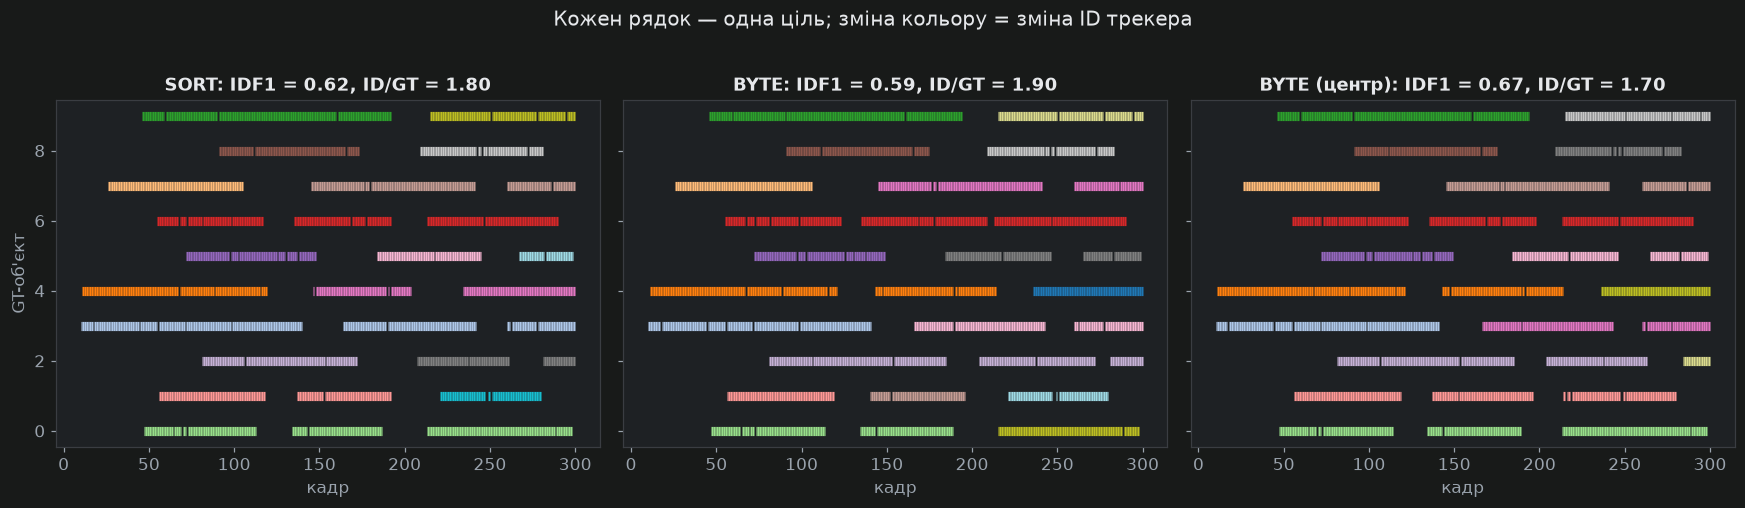

In [7]:
def gt_to_track(frames, hyp, iou_thr=0.5):
    """Який track-id покриває кожен GT-об'єкт у кожному кадрі."""
    by_t = {}
    for t, tid, *b in hyp:
        by_t.setdefault(t, []).append((tid, b))
    lanes = {}
    for t, objs in enumerate(frames):
        Hh = by_t.get(t, [])
        if not objs or not Hh:
            continue
        M = iou_matrix([o[1:] for o in objs], [h[1] for h in Hh])
        r, c = linear_sum_assignment(-M)
        for gi, hi in zip(r, c):
            if M[gi, hi] >= iou_thr:
                lanes.setdefault(objs[gi][0], []).append((t, Hh[hi][0]))
    return lanes

fig, axs = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (name, h) in zip(axs, hyps.items()):
    id_timeline(ax, gt_to_track(frames, h), f"{name}: IDF1 = {rows[name]['IDF1']:.2f}, ID/GT = {rows[name]['IDs_per_GT']:.2f}")
axs[0].set_ylabel('GT-об\'єкт')
fig.suptitle('Кожен рядок — одна ціль; зміна кольору = зміна ID трекера', y=1.02)
plt.tight_layout(); plt.show()

**Що видно.** «Наївний» BYTE тримає ціль у кадрі частіше (менше FN, вищий MOTA), але обрізаний у укритті бокс псує модель розміру в Калмані — на виході з укриття трек не збігається з повним боксом і народжується новий ID. MOTA і IDF1 тут **розходяться** — це та сама пастка, що на слайді «MOTA, IDF1 і HOTA: чому MOTA обирає не той трекер».

### 5. Кілька сцен: чи стабільний висновок

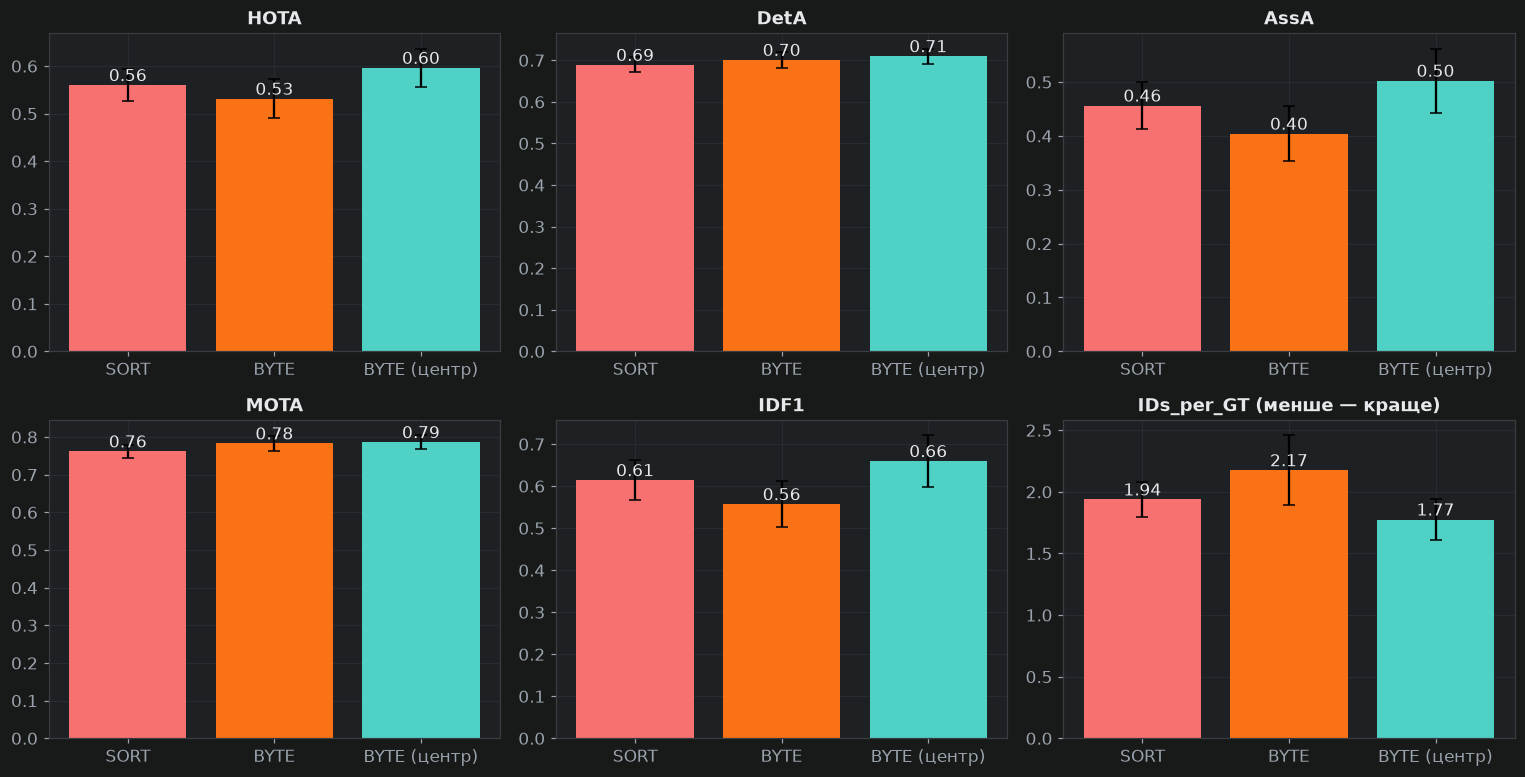

середнє по 8 сценах        HOTA       DetA       AssA       MOTA       IDF1 IDs_per_GT
SORT                      0.560      0.689      0.456      0.762      0.614      1.938
BYTE                      0.531      0.701      0.404      0.783      0.557      2.175
BYTE (центр)              0.596      0.710      0.502      0.786      0.660      1.775


In [8]:
from mdmt import run_trackeval, has_trackeval

SEEDS = range(8)
agg = {k: [] for k in VARIANTS}
gt8, hyp8 = {}, {k: {} for k in VARIANTS}
for sd in SEEDS:
    fr = make_gt(seed=sd); de = detect(fr, seed=sd)
    gt8[f'syn{sd}'] = fr
    for k, v in VARIANTS.items():
        h = run_tracker(de, **v)
        hyp8[k][f'syn{sd}'] = h
        agg[k].append(evaluate(fr, h))

# HOTA з розкладом — лише офіційний TrackEval (слайд 10); без нього лишаються MOTA / IDF1 / ID/GT
rows = [['MOTA', 'IDF1', 'IDs_per_GT']]
if has_trackeval():
    tag = {k: k.replace(' ', '_').replace('(', '').replace(')', '') for k in VARIANTS}   # назви трекерів — без пробілів
    te = run_trackeval(gt8, {tag[k]: hyp8[k] for k in VARIANTS}, run='demo1_syn')
    for k in VARIANTS:
        for r, name in zip(agg[k], gt8):
            r.update({m: te[tag[k]][name][m] for m in ('HOTA', 'DetA', 'AssA')})
    rows.insert(0, ['HOTA', 'DetA', 'AssA'])
else:
    print('TrackEval не встановлено — лише спрощені MOTA / IDF1 / ID/GT')

cols = [C['sort'], C['byte'], C['bytec']]
fig, axs = plt.subplots(len(rows), 3, figsize=(14, 3.6 * len(rows)), squeeze=False)
for ax_row, row in zip(axs, rows):
    for ax, m in zip(ax_row, row):
        means = [np.mean([r[m] for r in agg[k]]) for k in VARIANTS]
        stds = [np.std([r[m] for r in agg[k]]) for k in VARIANTS]
        bars_with_err(ax, list(VARIANTS), means, stds, cols, m + (' (менше — краще)' if m == 'IDs_per_GT' else ''))
plt.tight_layout(); plt.show()

names = [m for row in rows for m in row]
print(f"{'середнє по 8 сценах':20s}" + ''.join(f'{m:>11s}' for m in names))
for k in VARIANTS:
    print(f'{k:20s}' + ''.join(f"{np.mean([r[m] for r in agg[k]]):11.3f}" for m in names))

**Розклад HOTA.** «Наївний» BYTE підвищує **DetA**: слабкі бокси тримають ціль у кадрі, тому й MOTA росте. Але він знижує **AssA**: обрізані в укритті бокси рвуть ідентичність. У підсумку HOTA падає. BYTE (центр) кращий за обома складовими. Саме це означає «HOTA показує, що лікувати: детектор чи асоціацію» на слайді 9. MOTA обирає «наївний» BYTE, а HOTA та IDF1 одностайно обирають BYTE (центр).

### 6. Коли BYTE узагалі допомагає: частка слабких детекцій в укритті

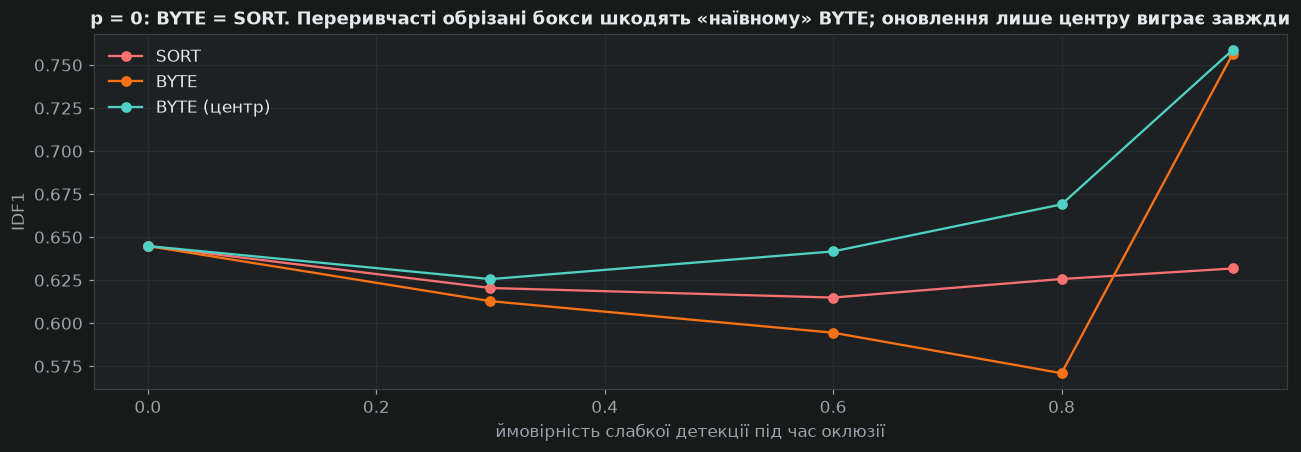

In [9]:
P_OCC = [0.0, 0.3, 0.6, 0.8, 0.95]
curve = {k: [] for k in VARIANTS}
for p in P_OCC:
    vals = {k: [] for k in VARIANTS}
    for sd in range(10):
        fr = make_gt(seed=sd); de = detect(fr, seed=sd, p_occ=p)
        for k, v in VARIANTS.items():
            vals[k].append(evaluate(fr, run_tracker(de, **v))['IDF1'])
    for k in VARIANTS:
        curve[k].append(np.mean(vals[k]))

plt.figure(figsize=(14, 4.2))
for (k, y), col in zip(curve.items(), cols):
    plt.plot(P_OCC, y, 'o-', color=col, label=k)
plt.xlabel('ймовірність слабкої детекції під час оклюзії'); plt.ylabel('IDF1')
plt.title('p = 0: BYTE = SORT. Переривчасті обрізані бокси шкодять «наївному» BYTE; оновлення лише центру виграє завжди')
plt.legend(); plt.show()

**Як читати криву.** Коли слабкі детекції в укритті переривчасті (p ≈ 0.3–0.8), обрізані бокси то приходять, то зникають, і модель розміру в Калмані «розхитується» — наївний BYTE опиняється нижче за SORT. Коли вони майже безперервні (p ≈ 0.95), розмір встигає підлаштуватись і обидва BYTE виграють. Варіант з оновленням лише центру не гірший за SORT за жодного p.

### Висновки для слайда

1. Детекції ті самі — змінюється лише асоціація.
2. Слабкі бокси корисні, **якщо використати їх правильно**: оновлювати центр, але не розмір.
3. MOTA обирає «наївний» BYTE, а HOTA та IDF1 — BYTE (центр). Розклад HOTA пояснює чому: DetA ↑, AssA ↓. У звітах — HOTA з розкладом + IDF1 (правило слайда 9).

### Що покрутити самостійно
- `SHRINK = 1.0` — укриття не обрізає бокс. Що стане з «наївним» BYTE?
- `accel` у `make_gt` — маневровість цілі. При якому значенні SORT перестає «перекочуватись» через укриття на самій предикції?
- `max_age` при 8 FPS проти 30 FPS: переведіть у секунди й подивіться на `ID/GT`.

In [10]:
# Експорт у формат MOTChallenge для TrackEval (frame, id, x, y, w, h, conf, -1, -1, -1)
import os
def export_mot(frames, hyp, out_dir='mot_export', name='BYTE_center'):
    os.makedirs(out_dir, exist_ok=True)
    with open(f'{out_dir}/gt.txt', 'w') as f:
        for t, objs in enumerate(frames):
            for oid, cx, cy, w, h in objs:
                f.write(f'{t+1},{oid+1},{cx-w/2:.1f},{cy-h/2:.1f},{w:.1f},{h:.1f},1,1,1\n')
    with open(f'{out_dir}/{name}.txt', 'w') as f:
        for t, tid, cx, cy, w, h in hyp:
            f.write(f'{t+1},{tid},{cx-w/2:.1f},{cy-h/2:.1f},{w:.1f},{h:.1f},1,-1,-1,-1\n')
    return out_dir

print('Експортовано в', export_mot(frames, hyps['BYTE (центр)']))

Експортовано в mot_export


### 7. Перевірка на реальних траєкторіях: MDMT

Висновки §4–§6 отримано на синтетиці. Перевіримо їх на **реальних траєкторіях** з MDMT: аерозйомка з дрона, перехрестя, авто 30–75 px. Беремо пару **48**: найдинамічніша з 17 повних пар (авто 10–13 px за кадр, ~200 переходів «видно ↔ перекрито» на кожен дрон).

**Чому детектор симульований.** Ми перевірили готовий COCO YOLO11m на цих кадрах: recall ≤ 4 % навіть при score ≥ 0.1. Надир, сутінки й малі цілі — це доменний зсув зі слайда 34. Тому детекції генеруємо з GT так само, як у §1, але **оклюзії реальні**: MDMT позначає кожен бокс, перекритий іншим об'єктом чи деревом або обрізаний краєм кадру, і саме ці бокси отримують слабкий score і обрізаний розмір. Детекції для всіх трекерів, як і раніше, однакові.

Дані: `python tools/fetch_mdmt.py --seqs 48` (≈ 0.6 ГБ, з кореня репозиторію). Без них розділ пропускається.
Метрики — офіційний **TrackEval** (`pip install git+https://github.com/JonathonLuiten/TrackEval.git`); без нього — спрощений `evaluate` з §3.

In [15]:
import sys
from pathlib import Path
from mdmt import load_boxes, frames_dir, frame_path, run_trackeval, has_trackeval

SEQ = '48'
try:
    N_FR = {d: len(list(frames_dir(SEQ, d).glob('*.jpg'))) for d in (1, 2)}
    MDMT_OK = True
except FileNotFoundError as e:
    MDMT_OK = False
    print(e)
TE_OK = has_trackeval()
if not TE_OK:
    print('TrackEval не встановлено — рахуємо спрощеним evaluate з §3 (без HOTA).')
print(f'MDMT: {MDMT_OK}, TrackEval: {TE_OK}')

MDMT: True, TrackEval: True


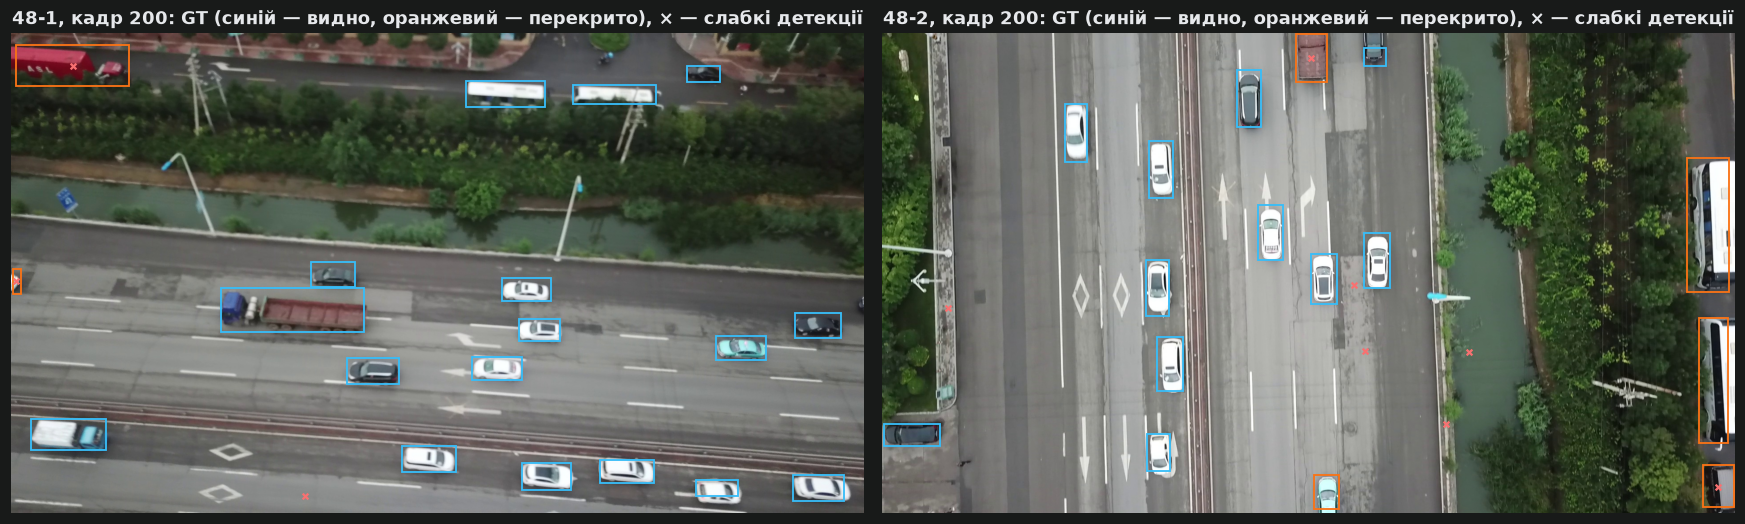

In [16]:
def detect_mdmt(seq, drone, p_vis=0.95, p_occ=0.8, occ_score=(0.15, 0.45), shrink=SHRINK,
                fp_rate=3.0, jitter=1.5, classes=('car',), seed=0):
    """Симульований детектор на реальних траєкторіях MDMT: як detect() з §1,
    але «укриття» — це прапорець occluded з розмітки, а не смуги в кадрі.
    Повертає (gt, dets): gt — кадри у форматі make_gt, dets — масиви (cx, cy, w, h, score)."""
    rng = np.random.default_rng(seed)
    n = N_FR[drone]
    gt = [[] for _ in range(n)]
    out = [[] for _ in range(n)]
    for t, tid, x, y, w, h, _, occ in load_boxes(seq, drone, classes):
        cx, cy = x + w / 2, y + h / 2
        gt[t].append((tid, cx, cy, w, h))
        if rng.random() > (p_occ if occ else p_vis):
            continue
        s = rng.uniform(*occ_score) if occ else rng.uniform(0.6, 0.95)
        bw, bh = w, h
        if occ:  # перекрито: видно лише частину вздовж довшої сторони
            bw, bh = (w * shrink, h) if w >= h else (w, h * shrink)
        out[t].append([cx + rng.normal(0, jitter), cy + rng.normal(0, jitter),
                       bw * (1 + rng.normal(0, 0.03)), bh * (1 + rng.normal(0, 0.03)), s])
    for t in range(n):
        for _ in range(rng.poisson(fp_rate)):
            out[t].append([rng.uniform(0, 1920), rng.uniform(0, 1080), rng.uniform(25, 70),
                           rng.uniform(25, 70), rng.uniform(0.1, 0.5)])
    return gt, [np.array(d, float).reshape(-1, 5) for d in out]


if MDMT_OK:
    from PIL import Image
    t_show = 200
    fig, axs = plt.subplots(1, 2, figsize=(16, 4.8))
    for ax, d in zip(axs, (1, 2)):
        gt_d, de_d = detect_mdmt(SEQ, d)
        ax.imshow(Image.open(frame_path(SEQ, d, t_show)))
        occ_ids = {r[1] for r in load_boxes(SEQ, d, ['car']) if r[0] == t_show and r[7]}
        for tid, cx, cy, w, h in gt_d[t_show]:
            ax.add_patch(plt.Rectangle((cx - w / 2, cy - h / 2), w, h, fill=False, lw=1.2,
                                       ec=C['byte'] if tid in occ_ids else C['gt']))
        weak = de_d[t_show][de_d[t_show][:, 4] < 0.6]
        ax.scatter(weak[:, 0], weak[:, 1], s=14, c=C['sort'], marker='x')
        ax.set_title(f'{SEQ}-{d}, кадр {t_show}: GT (синій — видно, оранжевий — перекрито), × — слабкі детекції')
        ax.axis('off')
    plt.tight_layout(); plt.show()

**30 FPS проти 10 FPS.** Окрім трьох варіантів асоціації, проженемо ту саму сцену з кожним третім кадром (10 FPS). Так виглядає вужчий канал або повільніший edge-вузол (слайди 15 і 42). `max_age` лишаємо 30 кадрів — у секундах при 10 FPS це вже 3 с замість 1 с.

In [17]:
if MDMT_OK:
    STRIDES = {'fps30': 1, 'fps10': 3}
    gt7, hyp7 = {}, {k: {} for k in VARIANTS}
    for d in (1, 2):
        gt_d, de_d = detect_mdmt(SEQ, d, seed=0)
        for tag, s in STRIDES.items():
            name = f'{SEQ}-{d}_{tag}'
            gt7[name] = gt_d[::s]
            for k, v in VARIANTS.items():
                hyp7[k][name] = run_tracker(de_d[::s], **v)

    def show(tag):
        names = [n for n in gt7 if n.endswith(tag)]
        if TE_OK:
            te = run_trackeval({n: gt7[n] for n in names},
                               {k.replace(' ', '_').replace('(', '').replace(')', ''): {n: h[n] for n in names}
                                for k, h in hyp7.items()},
                               run=f'demo1_{tag}', fps={n: 30 / STRIDES[tag] for n in names})
            print(f"{tag}: {'':14s} {'HOTA':>6s} {'DetA':>6s} {'AssA':>6s} {'MOTA':>6s} {'IDF1':>6s} {'IDSW':>5s}")
            for k, r in zip(VARIANTS, te.values()):
                c = r['COMBINED_SEQ']
                print(f"{'':7s}{k:14s} {c['HOTA']:6.3f} {c['DetA']:6.3f} {c['AssA']:6.3f} {c['MOTA']:6.3f} {c['IDF1']:6.3f} {c['IDSW']:5d}")
        else:
            print(f"{tag}: {'':14s} {'MOTA':>6s} {'IDF1':>6s} {'IDSW':>5s}")
            for k in VARIANTS:
                rs = [evaluate(gt7[n], hyp7[k][n]) for n in names]
                print(f"{'':7s}{k:14s} {np.mean([r['MOTA'] for r in rs]):6.3f} {np.mean([r['IDF1'] for r in rs]):6.3f} "
                      f"{sum(r['IDSW'] for r in rs):5d}")

    show('fps30'); print(); show('fps10')

fps30:                  HOTA   DetA   AssA   MOTA   IDF1  IDSW
       SORT            0.708  0.693  0.723  0.723  0.800    19
       BYTE            0.718  0.705  0.732  0.739  0.810    19
       BYTE (центр)    0.716  0.703  0.730  0.734  0.807    19

fps10:                  HOTA   DetA   AssA   MOTA   IDF1  IDSW
       SORT            0.604  0.566  0.645  0.598  0.705   137
       BYTE            0.610  0.573  0.650  0.606  0.711   137
       BYTE (центр)    0.608  0.571  0.648  0.605  0.710   137


fps10:                  HOTA   DetA   AssA   MOTA   IDF1  IDSW
       SORT            0.604  0.566  0.645  0.598  0.705   137
       BYTE            0.610  0.573  0.650  0.606  0.711   137
       BYTE (центр)    0.608  0.571  0.648  0.605  0.710   137


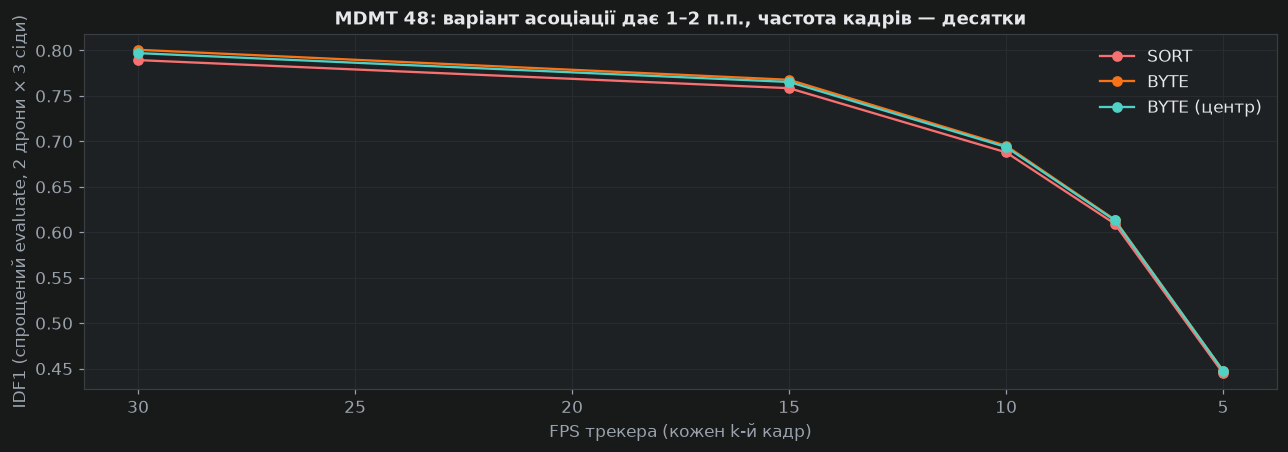

In [18]:
if MDMT_OK:
    FPS_GRID = {30: 1, 15: 2, 10: 3, 7.5: 4, 5: 6}
    curve7 = {k: [] for k in VARIANTS}
    for fps, s in FPS_GRID.items():
        vals = {k: [] for k in VARIANTS}
        for d in (1, 2):
            for sd in range(3):
                gt_d, de_d = detect_mdmt(SEQ, d, seed=sd)
                for k, v in VARIANTS.items():
                    vals[k].append(evaluate(gt_d[::s], run_tracker(de_d[::s], **v))['IDF1'])
        for k in VARIANTS:
            curve7[k].append(np.mean(vals[k]))

    plt.figure(figsize=(14, 4.2))
    for (k, y), col in zip(curve7.items(), cols):
        plt.plot(list(FPS_GRID), y, 'o-', color=col, label=k)
    plt.gca().invert_xaxis()
    plt.xlabel('FPS трекера (кожен k-й кадр)'); plt.ylabel('IDF1 (спрощений evaluate, 2 дрони × 3 сіди)')
    plt.title(f'MDMT {SEQ}: варіант асоціації дає 1–2 п.п., частота кадрів — десятки')
    plt.legend(); plt.show()

**Що видно на реальних траєкторіях.**

1. **Детекції ті самі — і різниця між SORT, BYTE і BYTE (центр) тут лише 1–2 п.п.** При 30 FPS авто зсувається на 10–13 px за кадр за бокса 30–75 px: Калман сам «перекочує» ціль через коротку оклюзію, і другому етапу асоціації майже нічого рятувати. Висновок §6 про «наївний» BYTE на цій сцені не відтворюється — і це нормально: він залежав від того, як довго й переривчасто ціль сидить за укриттям.
2. **Частота кадрів важить на порядок більше.** При 10 FPS зсув за кадр порівнюваний із розміром бокса, IoU падає до нуля (слайд 14: «мала швидка ціль: IoU ≈ 0»), і ціль розпадається на кілька ID — у будь-якому варіанті асоціації. Лікування — не інший трекер, а CMC, модель руху й вартість не лише на IoU (слайди 12, 15, 19).
3. **HOTA показує, що при 10 FPS падають обидві складові.** AssA — через розриви треків (IDSW зростає в рази). DetA — хоча детекції ті самі: трекер видає бокс, лише коли зіставив його з треком, а при 10 FPS частина детекцій не проходить IoU-гейт і зникає з виходу. Ще частину з'їдає `n_init`: кожен новий фрагмент 3 кадри непідтверджений, при 10 FPS це 0.3 с без треку (з `n_init=1` повертається ≈ 3 п.п. пропусків з ≈ 11 — ціною ще більшої кількості ID switch). Тобто погана асоціація б'є і по «детекційній» метриці — і одна MOTA цього розкладу не покаже (правило слайда 9; `n_init` і `max_age` — у секундах, слайд 8).

**Головне: висновок із синтетики треба перевіряти на своєму домені (слайд 21).**

### Що покрутити самостійно
- `SEQ = '46'`: камера дрейфує повільно й плавно. Чи лишається там хоч якась різниця між трекерами?
- `classes=('person',)`: люди тут по 10–20 px. Що відбувається з IoU-асоціацією вже при 30 FPS?
- `max_age` у §2 переведіть у секунди для 10 FPS (слайд 17) і порівняйте ID/GT.